The goal is to segment songs into meaningful performance groups using chart-performance, without creating an arbitrary "best song" ranking.

### Objective

We will identify song-performance segments such as:

1) Emerging / Short-Lived 
2) High-Impact Hits
3) Longevity Hits
4) Mega Hits
5) Moderate Performers

We'll use unsupervised learning, primarily:

K-Means, PCA, Cluster profiling, Cluster Visualization, Cluster interpretation, Optional comparison with rule-based segments.

Important: This notebook uses chart-performance variables for segmentation. It is descriptive/analytical, not a predictive model, so using wks, total, PkStreams, etc here is appropriate.

Identify distinct song-performance profiles using unsupervised machine learning.

#### Techniques

- K-Means Clustering
- StandardScaler
- PCA
- Cluster profiling
- Performance distribution analysis
- Segment visualization

#### Key Questions

1. What distinct types of chart-performing songs exist?
2. Which songs are driven by longevity?
3. Which songs are driven by high streaming impact?
4. Which songs combine strong peak performance and longevity?
5. How large is each performance segment?
6. Which artists appear frequently within each segment?

In [1]:
# Import Libraries

import pandas as pd 
import numpy as np 

import matplotlib.pyplot as plt 
import seaborn as sns 

from pathlib import Path 

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans 
from sklearn.decomposition import PCA 
from sklearn.metrics import silhouette_score 


from IPython.display import display

In [2]:
# Define Project Paths

PROJECT_ROOT = Path(
    r"C:\Users\Sanu\OneDrive\Desktop\Spotify-Global-Hit-Intelligence"
)

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "spotify_global_chart_totals_lyrics_cleaned.csv"
)

OUTPUT_DIR = (
    PROJECT_ROOT
    / "outputs"
    / "figures"
    / "hit_segmentation"
)

TABLE_DIR = (
    PROJECT_ROOT
    / "outputs"
    / "tables"
    / "hit_segmentation"
)

PROCESSED_DIR = (
    PROJECT_ROOT
    / "data"
    / "processed"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)

Project root: C:\Users\Sanu\OneDrive\Desktop\Spotify-Global-Hit-Intelligence


In [3]:
# Load Dataset

df = pd.read_csv(
    DATA_PATH,
    low_memory=False
)

print("Dataset shape:", df.shape)

display(df.head())

Dataset shape: (8058, 29)


,artist and title,wks,t10,pk,PkStreams,total,artist name,song name,lyrics,peak_duration,...,log_PkStreams,log_t10,lyrics_original,lyrics_available,lyrics_clean,lyrics_char_count,lyrics_word_count,lyrics_line_count,words_per_line,top10_reached
0,The Weeknd - Blinding Lights,347,64,1,52375259,5441240333,The Weeknd,Blinding Lights,Yeah I've been tryna call I've been on my own ...,13.0,...,17.773945,4.174387,Yeah I've been tryna call I've been on my own ...,True,Yeah I've been tryna call I've been on my own ...,1230,259,1,259.0,1
1,Ed Sheeran - Shape of You,424,34,1,64217796,4470842634,Ed Sheeran,Shape of You,The club isn't the best place to find a lover ...,14.0,...,17.977791,3.555348,The club isn't the best place to find a lover ...,True,The club isn't the best place to find a lover ...,3139,688,1,688.0,1
2,Harry Styles - As It Was,218,60,1,78460903,4417264164,Harry Styles,As It Was,﻿ As It Was - Harry Styles Come on Harry we wa...,11.0,...,18.178111,4.110874,﻿ As It Was - Harry Styles Come on Harry we wa...,True,﻿ As It Was - Harry Styles Come on Harry we wa...,1143,243,1,243.0,1
3,The Neighbourhood - Sweater Weather,333,0,16,21624450,4142643719,The Neighbourhood,Sweater Weather,And all I am is a man I want the world in my h...,NaN,...,16.889335,NaN,And all I am is a man I want the world in my h...,True,And all I am is a man I want the world in my h...,1678,345,1,345.0,0
4,Lewis Capaldi - Someone You Loved,343,15,4,24962682,3933581891,Lewis Capaldi,Someone You Loved,I'm going under and this time I fear there's n...,NaN,...,17.032893,2.772589,I'm going under and this time I fear there's n...,True,I'm going under and this time I fear there's n...,1555,323,1,323.0,1


5. Check Required Columns

Our segmentation will use:

wks, t10, pk, PkStreams, total

In [4]:
# Check them

SEGMENTATION_COLUMNS = [
    "wks",
    "t10",
    "pk",
    "PkStreams",
    "total"
]

missing_columns = [
    col 
    for col in SEGMENTATION_COLUMNS
    if col not in df.columns
]

print("Missing columns:", missing_columns)

Missing columns: []


In [5]:
# 6. Create Segmentation Dataset - We don't want artist/song text columns entering K-Means 

seg_df = df[
    [
        "artist name",
        "song name",
        "wks",
        "t10",
        "pk",
        "PkStreams",
        "total"
    ]
].copy()

print("Segmentation dataset:", seg_df.shape)

Segmentation dataset: (8058, 7)


In [6]:
# 7. Create Performance Features - We will create a few useful derived measures.

# Peak position score - because lower pk means better performance

seg_df["peak_position_score"] = (
    247 - seg_df["pk"]
) / 246

Interpretation

Peak # 1 -> approximately 1
Peak # 246 -> approximately 0 

In [7]:
# 7.2 Top-10 ratio

seg_df["top10_week_ratio"] = (
    seg_df["t10"] /
    seg_df["wks"].replace(0, np.nan)
)

This tells us what proportion of a song's chart life was spent in the Top 10

In [8]:
# 7.3 Streams per week

seg_df["streams_per_week"] = (
    seg_df["total"] /
    seg_df["wks"].replace(0, np.nan)
)

In [9]:
# 7.4 Peak streams share

seg_df["peak_stream_share"] = (
    seg_df["PkStreams"] /
    seg_df["total"].replace(0, np.nan)
)

In [10]:
# 8. Inspect the Features

display(
    seg_df[
        [
            "wks",
            "t10",
            "pk",
            "PkStreams",
            "total",
            "peak_position_score",
            "top10_week_ratio",
            "streams_per_week",
            "peak_stream_share"
        ]
    ].describe().T
)

,count,mean,std,min,25%,50%,75%,max
wks,8058.0,1.551055e+01,3.092141e+01,1.000000,1.000000e+00,4.000000e+00,1.700000e+01,4.570000e+02
t10,8058.0,8.252668e-01,3.768298e+00,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,7.100000e+01
pk,8058.0,8.366418e+01,6.012591e+01,1.000000,3.000000e+01,7.400000e+01,1.320000e+02,2.460000e+02
PkStreams,8058.0,1.156726e+07,1.025781e+07,166910.000000,5.368128e+06,8.941470e+06,1.414555e+07,1.288961e+08
total,8058.0,1.419280e+08,3.394366e+08,166910.000000,8.916825e+06,2.798093e+07,1.188043e+08,5.441240e+09
peak_position_score,8058.0,6.639667e-01,2.444143e-01,0.004065,4.674797e-01,7.032520e-01,8.821138e-01,1.000000e+00
top10_week_ratio,8058.0,1.692617e-02,6.667971e-02,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
streams_per_week,8058.0,7.766864e+06,4.340062e+06,164271.000000,4.878707e+06,7.310585e+06,1.007203e+07,5.055226e+07
peak_stream_share,8058.0,4.496182e-01,3.856365e-01,0.004007,8.700628e-02,3.212365e-01,1.000000e+00,1.000000e+00


In [11]:
# 9. Handle Skewed Variables 
# total,PkStreams, wks and streams_per_week are heavily right-skewed
# Using raw values in K-Means would allow extremely large hits to dominate the distance calculations.

# Therefore, use log transformations

seg_df["log_wks"] = np.log1p(seg_df["wks"])

seg_df["log_t10"] = np.log1p(seg_df["t10"])

seg_df["log_PkStreams"] = np.log1p(
    seg_df["PkStreams"]
)

seg_df["log_total"] = np.log1p(
    seg_df["total"]
)

seg_df["log_streams_per_week"] = np.log1p(
    seg_df["streams_per_week"]
)

In [12]:
# 10. Select Clustering features - for the first segmentation model, use:

CLUSTER_FEATURES = [
    "log_wks",
    "log_t10",
    "peak_position_score",
    "log_PkStreams",
    "log_total",
    "top10_week_ratio"
]

print("Clustering features:")
for feature in CLUSTER_FEATURES:
    print("-", feature)

Clustering features:
- log_wks
- log_t10
- peak_position_score
- log_PkStreams
- log_total
- top10_week_ratio


Why these?

Feature                         Captures

log_wks                         Longevity

log_t10                         Depth of Top-10 performance

peak_position_score             Peak chart strength

log_PkStreams                   Peak streaming impact 

log_total                       Overall streaming impact

top10_week_ratio                Quality/depth of chart run

In [13]:
# Handle Missing / Infinite Values

X = seg_df[CLUSTER_FEATURES].copy()

X = X.replace(
    [np.inf, -np.inf],
    np.nan
)

print("Missing Values:")
print(X.isna().sum())

Missing Values:
log_wks                0
log_t10                0
peak_position_score    0
log_PkStreams          0
log_total              0
top10_week_ratio       0
dtype: int64


In [14]:
# 12. Standardize Features

# K-Means uses distances, so scaling is essential

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Scaled matrix shape:", X_scaled.shape)

Scaled matrix shape: (8058, 6)


In [15]:
# 13. Determine the Number of Clusters

# K-MEANS MODEL SELECTION

# Inertia + Silhouette Score

from sklearn.cluster import KMeans 
from sklearn.metrics import silhouette_score as sklearn_silhouette_score

# Define K values
K_VALUES = list(range(2, 9))

inertias = []
silhouette_scores = []

for k in K_VALUES:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(X_scaled)

    # Store inertia
    inertias.append(model.inertia_)

    # Store silhouette score
    sil_score = sklearn_silhouette_score(
        X_scaled,
        labels
    )

    silhouette_scores.append(sil_score)

# Validation

print("K values:", K_VALUES)
print("Number of inertia values:", len(inertias))
print("Number of silhouette scores:", len(silhouette_scores))

assert len(K_VALUES) == len(inertias)
assert len(K_VALUES) == len(silhouette_scores)


# Evaluation table

cluster_evaluation = pd.DataFrame({
    "k": K_VALUES,
    "inertia": inertias,
    "silhouette_score": silhouette_scores
})

display(cluster_evaluation)


K values: [2, 3, 4, 5, 6, 7, 8]
Number of inertia values: 7
Number of silhouette scores: 7


,k,inertia,silhouette_score
0,2,29708.939625,0.403954
1,3,17990.595210,0.405116
2,4,14452.144467,0.337836
3,5,12685.044001,0.349438
4,6,11052.358618,0.356675
5,7,9569.409746,0.360427
6,8,8333.299967,0.365685


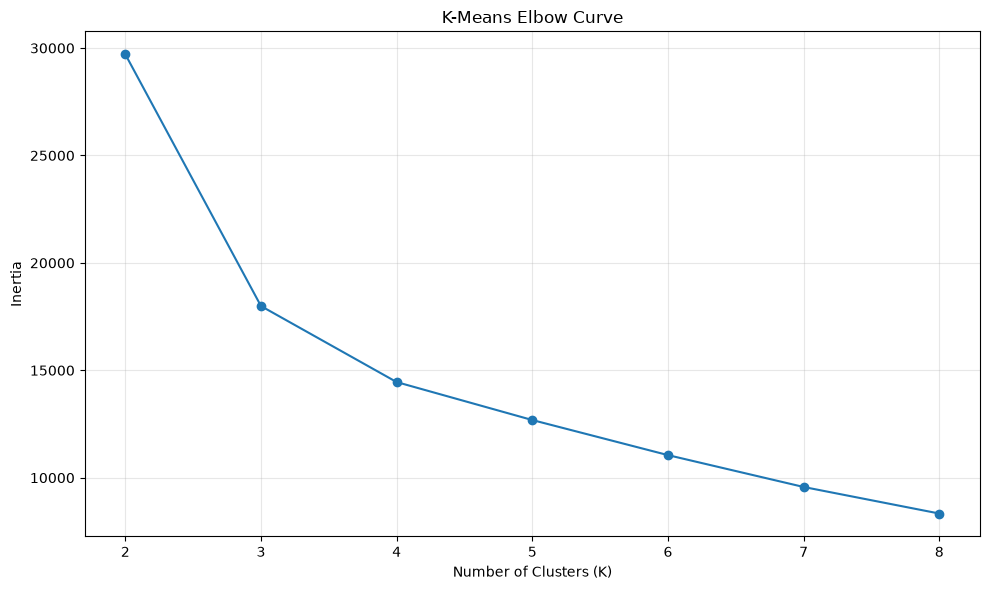

In [16]:
# Plot 1- Elbow Curve

plt.figure(figsize=(10, 6))

plt.plot(
    K_VALUES,
    inertias,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("K-Means Elbow Curve")

plt.xticks(K_VALUES)
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "kmeans_elbow_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

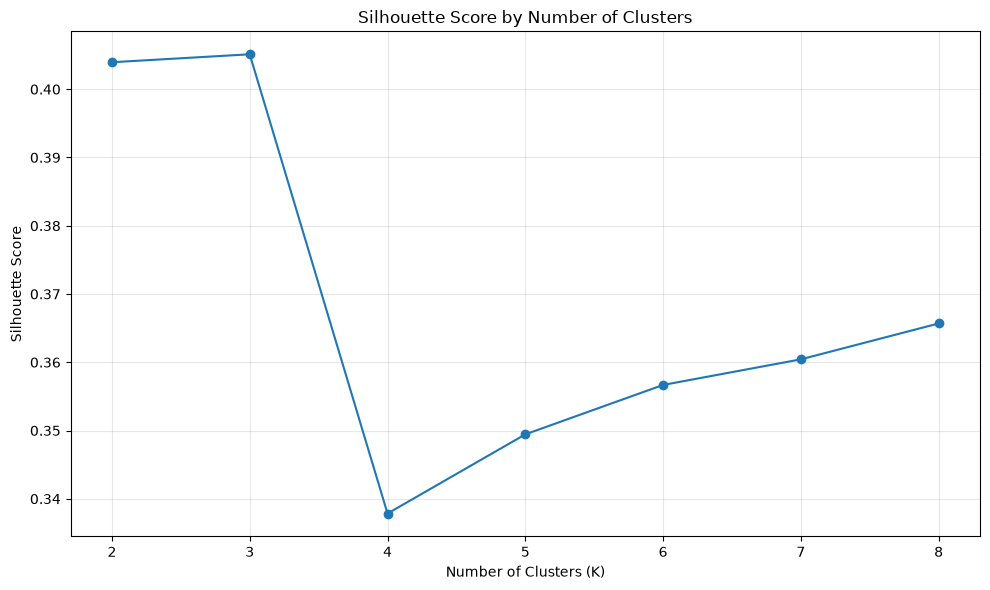

In [17]:
# Plot 2 - Silhouette Score

plt.figure(figsize=(10, 6))

plt.plot(
    K_VALUES,
    silhouette_scores,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score by Number of Clusters")

plt.xticks(K_VALUES)
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "silhouette_scores.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [18]:
# Find the highest silhouette score

best_k_by_silhouette = (
    cluster_evaluation
    .loc[
        cluster_evaluation["silhouette_score"].idxmax(),
        "k"
    ]
)

best_score = (
    cluster_evaluation["silhouette_score"].max()
)

print(
    "Highest silhouette K:",
    best_k_by_silhouette
)

print(
    "Silhouette score:",
    round(best_score, 4)
)

Highest silhouette K: 3
Silhouette score: 0.4051


In [19]:
# Build the 3-cluster model

# FINAL K-MEANS MODEL - 3 PERFORMANCE SEGMENTS

N_CLUSTERS = 3

kmeans_final = KMeans(
    n_clusters = N_CLUSTERS,
    random_state = 42,
    n_init=20
)

seg_df["cluster"] = kmeans_final.fit_predict(
    X_scaled
)

print("Number of clusters:", N_CLUSTERS)
print("Cluster labels:", sorted(seg_df["cluster"].unique()))

Number of clusters: 3
Cluster labels: [np.int32(0), np.int32(1), np.int32(2)]


In [20]:
# Check cluster sizes

cluster_sizes = (
    seg_df["cluster"]
    .value_counts()
    .sort_index()
)

cluster_distribution = pd.DataFrame({
    "songs": cluster_sizes,
    "percentage": (
        cluster_sizes / len(seg_df) * 100
    )
})

display(cluster_distribution)

,songs,percentage
cluster,,
0,3680,45.668900
1,3784,46.959543
2,594,7.371556


In [21]:
# Profile the three clusters

cluster_profile = (
    seg_df
    .groupby("cluster")
    .agg(
        songs=("song name", "count"),

        median_weeks=("wks", "median"),
        mean_weeks= ("wks","mean"),

        median_top10_weeks = ("t10", "median"),
        mean_top10_weeks = ("t10", "mean"),

        median_peak = ("pk", "median"),
        mean_peak = ("pk", "mean"),

        median_peak_streams = ("PkStreams", "median"),
        median_total_streams = ("total", "median"),

        median_streams_per_week = (
            "streams_per_week",
            "median"
        ),

        median_t10_ratio = (
            "top10_week_ratio",
            "median"
        )

    )
)

cluster_profile["percentage"] = (
    cluster_profile["songs"]
    / len(seg_df)
    * 100
)


display(
    cluster_profile.round(2)
)

,songs,median_weeks,mean_weeks,median_top10_weeks,mean_top10_weeks,median_peak,mean_peak,median_peak_streams,median_total_streams,median_streams_per_week,median_t10_ratio,percentage
cluster,,,,,,,,,,,,
0,3680,13.0,20.95,0.0,0.07,38.0,45.34,12588185.5,86755235.5,8696224.66,0.00,45.67
1,3784,1.0,2.56,0.0,0.00,136.0,133.45,5606495.5,8506375.5,5368413.00,0.00,46.96
2,594,54.0,64.33,8.0,10.75,3.0,3.89,30349935.0,585829637.0,12659555.18,0.18,7.37


Don't name the clusters yet.

We need to see this output first.

For example, we may discover something like

Cluster 0 -> low total streams, short chart life
Cluster 1 -> long chart life, moderate streaming
Cluster 3 -> high streams, strong peak performance

But the actual results determine the names.

In [22]:
# PCA visualization
# Since we have calculated PCA earlier, recreate it using the final 3 clusters.

pca = PCA(
    n_components=2,
    random_state=42
)

X_pca = pca.fit_transform(X_scaled)

seg_df["PC1"] = X_pca[:, 0]
seg_df["PC2"] = X_pca[:, 1]

print(
    "PC1 explained variance:",
    round(pca.explained_variance_ratio_[0], 4)
)

print(
    "PC2 explained variance:",
    round(pca.explained_variance_ratio_[1], 4)
)

print(
    "Total explained varaince:",
    round(pca.explained_variance_ratio_.sum(), 4)
)

PC1 explained variance: 0.6257
PC2 explained variance: 0.1905
Total explained varaince: 0.8161


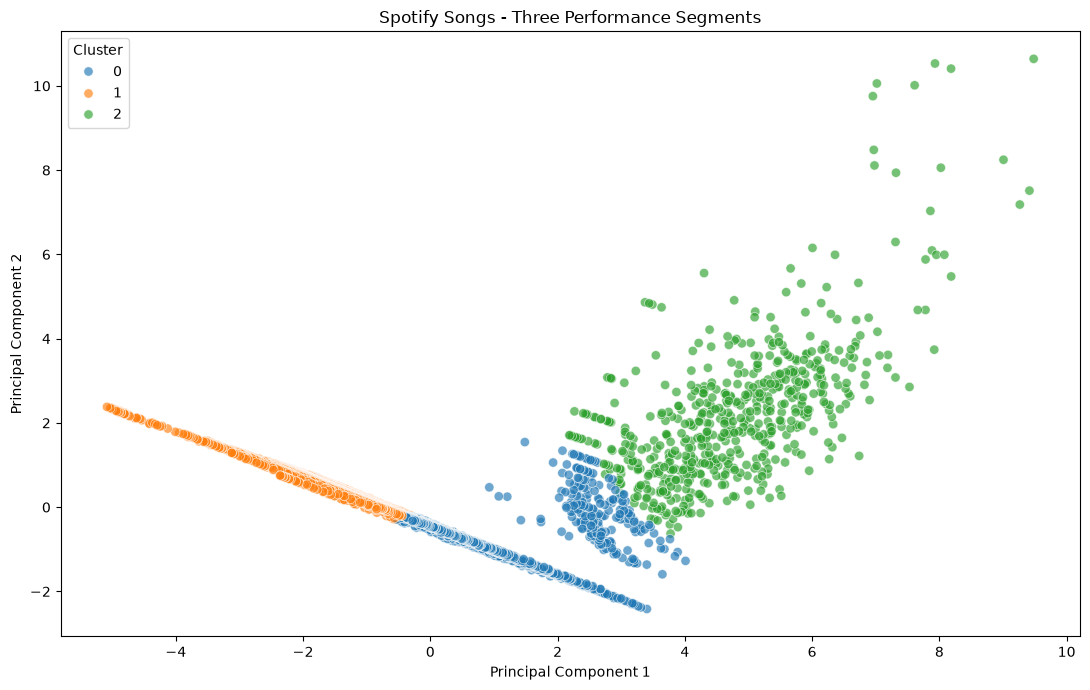

In [23]:
# Plot

plt.figure(figsize=(11, 7))


sns.scatterplot(
    data=seg_df,
    x="PC1",
    y="PC2",
    hue="cluster",
    palette="tab10",
    alpha=0.65,
    s=45
)

plt.title(
    "Spotify Songs - Three Performance Segments"
)


plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.legend(title="Cluster")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "pca_3_cluster_visualization.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [24]:
# Find representative songs - This will help us understand what each cluster actually represents.

distances = kmeans_final.transform(X_scaled)

seg_df["cluster_distance"] = (
    distances[
        np.arange(len(seg_df)),
        seg_df["cluster"].values
    ]
)

representative_songs = (
    seg_df
    .sort_values(
        ["cluster", "cluster_distance"]
    )
    .groupby("cluster")
    .head(10)
)

display(
    representative_songs[
        [
            "cluster",
            "artist name",
            "song name",
            "wks",
            "t10",
            "pk",
            "PkStreams",
            "total",
            "cluster_distance"
        ]
    ]
)

,cluster,artist name,song name,wks,t10,pk,PkStreams,total,cluster_distance
2447,0,C. Tangana,Tú Me Dejaste De Querer,12,0,42,11345919,83712117,0.143458
2265,0,Kylie Minogue,Santa Baby,13,0,52,12182973,95564875,0.157045
2463,0,Kygo,Like It Is,12,0,43,10760952,82439120,0.181850
2169,0,Megan Thee Stallion,Thot Shit,12,0,46,10676414,103136459,0.184538
2399,0,IVE,After LIKE,10,0,48,11766987,86426944,0.185859
2195,0,Kehlani,Nights Like This,13,0,37,11568466,101573739,0.191563
2420,0,ZAYN,A Whole New World,12,0,47,10541734,85313383,0.192898
2164,0,Anuel AA,Keii,13,0,37,12471842,103435785,0.193065
2131,0,Eliza Rose,B.O.T.A.,12,0,52,11003367,106426241,0.199513
2143,0,Ashe,Moral of the Story,12,0,42,13675094,105594686,0.202034


In [25]:
# Also inspect the strongest performers in each cluster

for cluster in sorted(seg_df["cluster"].unique()):

    print("\n" +  "=" * 70)
    print(f"CLUSTER {cluster}")
    print("=" * 70)

    display(
        seg_df[
            seg_df["cluster"] == cluster
        ][
            [
            "artist name",
            "song name",
            "wks",
            "t10",
            "pk",
            "PkStreams",
            "total"
        ]
        ]
        .sort_values(
            "total",
            ascending=False
        )
        .head(10)
    )


CLUSTER 0


,artist name,song name,wks,t10,pk,PkStreams,total
3,The Neighbourhood,Sweater Weather,333,0,16,21624450,4142643719
10,Billie Eilish,lovely,400,0,24,14081242,3514154790
13,Arctic Monkeys,I Wanna Be Yours,211,0,15,21021481,3362241618
14,Imagine Dragons,Believer,425,0,16,16864827,3353483545
15,Coldplay,Yellow,292,0,19,19818571,3146842043
17,Tom Odell,Another Love,265,0,15,20219891,3107580183
20,Vance Joy,Riptide,415,0,16,16836644,2983453847
26,The Weeknd,Die For You,223,0,12,22988828,2624144884
29,Lord Huron,The Night We Met,196,0,15,21456993,2586706406
31,The Police,Every Breath You Take,241,2,8,25306108,2548164516



CLUSTER 1


,artist name,song name,wks,t10,pk,PkStreams,total
2526,Ofenbach,Overdrive,9,0,157,9164205,78486060
2583,Beyoncé,Halo,21,0,149,4368364,75364876
2632,Freddie Dredd,Limbo,10,0,158,7971047,73588094
2652,Ramz,Barking,17,0,142,4678700,72135571
2657,Morgan Wallen,Cowgirls,8,0,173,9255746,71893488
2686,Creedence Clearwater Revival,Fortunate Son,8,0,158,9258708,70011692
2702,TV Girl,Not Allowed,8,0,165,9186131,69181599
2708,Manuel Turizo,Sola,14,0,156,5196275,68843722
2710,Neton Vega,Chiquita,8,0,159,9052776,68602539
2754,The White Stripes,Seven Nation Army,7,0,146,10112487,66543359



CLUSTER 2


,artist name,song name,wks,t10,pk,PkStreams,total
0,The Weeknd,Blinding Lights,347,64,1,52375259,5441240333
1,Ed Sheeran,Shape of You,424,34,1,64217796,4470842634
2,Harry Styles,As It Was,218,60,1,78460903,4417264164
4,Lewis Capaldi,Someone You Loved,343,15,4,24962682,3933581891
5,The Weeknd,Starboy,317,21,1,35360281,3857210959
6,Billie Eilish,BIRDS OF A FEATHER,114,71,1,66726270,3821072735
7,Lady Gaga,Die With A Smile,101,61,1,78624101,3797546382
8,Post Malone,Sunflower,346,31,1,34579416,3793341693
9,Ed Sheeran,Perfect,457,15,4,24763619,3730229095
11,Drake,One Dance,325,26,1,47782311,3414508398


This distinction is useful:

Representative songs: closest to the cluster center.
High-stream songs: examples of the strongest streaming outcomes within that cluster.

K evaluation - choose candidate K - inspect cluster profiles - interpret segments.


The K=3 segmentation is very interpretable, and the PCA plot supports the separation. The three clusters have clear differences.

Cluster 0 - Sustained Mid-Tier Performers

These songs generally:

1) remain on the chart for a meaningful period
2) have median 13 weeks
3) reach a median peak of # 38
4) accumulate substantially more total streams than Cluster 1
5) generally do not spend significant time in the Top 10

Your representative examples include songs with roughly 10-13 weeks on chart and peaks around # 37-52.

So this group represents durable chart presence without the extreme Top-10/ streaming performance of the biggest hits.

Cluster 1 - Short-Lived / Limited-Impact songs

This is the largest group:

1) 46.96% of songs
2) median chart life - 1 week
3) median peak = # 136
4) median total streams = 8.5M
5) median Top-10 weeks = 0

The representative songs strongly confirm this profile.

This cluster captures songs that appeared on the global chart but had relatively brief chart runs and limited peak positions.

Cluster 2 - Breakout Global Hits

This is the smallest cluster:

1) only 7.37% of songs
2) median chart life = 54 weeks
3) median peak = # 3
4) median Top-10 weeks = 8
5) median total streams = 585.8M
6) median peak streams = 30.3 M

This is a very distinct performance segment.

Examples include

1) ZEZE
2) Yandel 150
3) Strangers
4) DESPECHA
5) Black Beatles
6) Columbia
7) Dance the Night
8) MAMIII
9) Gucci Gang 

These songs demonstrate the combination of longevity, strong peak position, Top-10 presence and high cumulative streaming.


2. The PCA result is strong for visualization 
PC1 = 62.57% 
PC2 = 19.05%
Total = 81.61%

So the first two principal components explain 81.61% of the variance in the standardized clustering features.

That's useful for the portfolio because your 2D visualization captures a substantial portion of the underlying variation.

The plot also visually shows:

1) Cluster 1 concentrated on the lower-left 
2) Cluster 0 in the central region
3) Cluster 2 extending strongly toward the upper-right 

This aligns well with the cluster profiles.

In [26]:
# Now assign meaningful segment names

# ASSIGN INTERPRETABLE SEGMENT NAMES

cluster_names = {
    0: "Sustained Mid-Tier Performers",
    1: "Short-Lived / Limited-Impact Songs",
    2: "Breakout Global Hits"
}

seg_df["segment"] = seg_df["cluster"].map(cluster_names)

display(
    seg_df[
        [
            "cluster",
            "segment",
            "artist name",
            "song name",
            "wks",
            "t10",
            "pk",
            "total"
        ]
    ].head()
)

,cluster,segment,artist name,song name,wks,t10,pk,total
0,2,Breakout Global Hits,The Weeknd,Blinding Lights,347,64,1,5441240333
1,2,Breakout Global Hits,Ed Sheeran,Shape of You,424,34,1,4470842634
2,2,Breakout Global Hits,Harry Styles,As It Was,218,60,1,4417264164
3,0,Sustained Mid-Tier Performers,The Neighbourhood,Sweater Weather,333,0,16,4142643719
4,2,Breakout Global Hits,Lewis Capaldi,Someone You Loved,343,15,4,3933581891


In [27]:
# Verify the segment distribution

segment_distribution = (
    seg_df["segment"]
    .value_counts()
    .rename_axis("segment")
    .reset_index(name="songs")
)

segment_distribution["percentage"] = (
    segment_distribution["songs"]
    / len(seg_df)
    * 100
)

display(
    segment_distribution
)

,segment,songs,percentage
0,Short-Lived / Limited-Impact Songs,3784,46.959543
1,Sustained Mid-Tier Performers,3680,45.668900
2,Breakout Global Hits,594,7.371556


In [28]:
# Create the final segment profile - Let's make the portfolio table more readable

segment_summary = (
    seg_df
    .groupby("segment")
    .agg(
        songs=("song name", "count"),

        median_weeks=("wks", "median"),
        mean_weeks = ("wks", "mean"),

        median_top10_weeks = ("t10", "median"),
        mean_top10_weeks = ("t10", "mean"),

        median_peak_position=("pk", "median"),
        mean_peak_position=("pk", "mean"),

        median_peak_streams=("PkStreams", "median"),
        median_total_streams=("total", "median"),

        median_streams_per_week=(
            "streams_per_week",
            "median"
        ),

        median_top10_ratio=(
            "top10_week_ratio",
            "median"
        )

    )
)

segment_summary["percentage"] = (
    segment_summary["songs"]
    / len(seg_df)
    * 100
)

display(
    segment_summary.round(2)
)

,songs,median_weeks,mean_weeks,median_top10_weeks,mean_top10_weeks,median_peak_position,mean_peak_position,median_peak_streams,median_total_streams,median_streams_per_week,median_top10_ratio,percentage
segment,,,,,,,,,,,,
Breakout Global Hits,594,54.0,64.33,8.0,10.75,3.0,3.89,30349935.0,585829637.0,12659555.18,0.18,7.37
Short-Lived / Limited-Impact Songs,3784,1.0,2.56,0.0,0.00,136.0,133.45,5606495.5,8506375.5,5368413.00,0.00,46.96
Sustained Mid-Tier Performers,3680,13.0,20.95,0.0,0.07,38.0,45.34,12588185.5,86755235.5,8696224.66,0.00,45.67


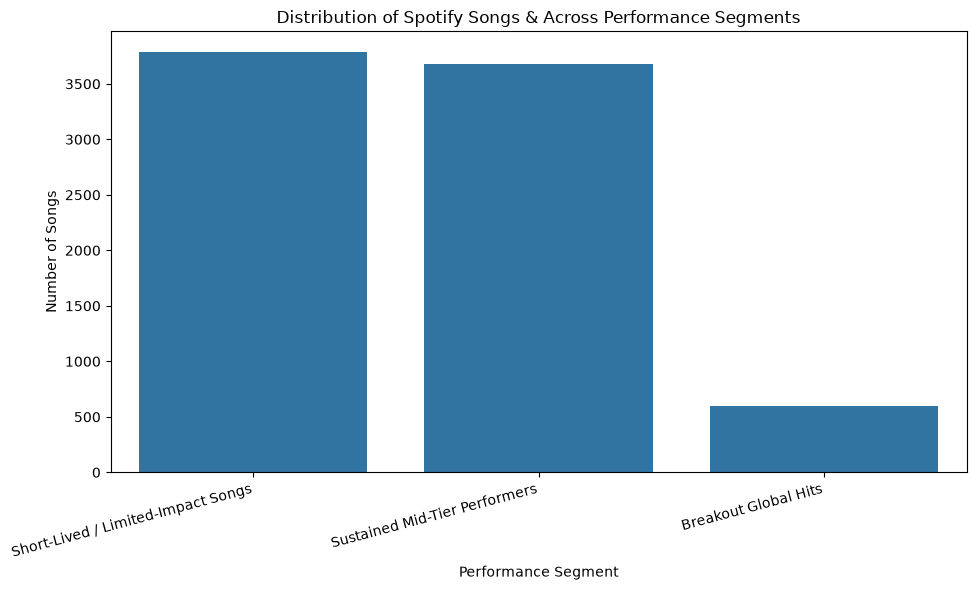

In [29]:
# Visualize the three segments

plt.figure(figsize=(10, 6))

sns.barplot(
    data=segment_distribution,
    x="segment",
    y="songs"
)

plt.xlabel("Performance Segment")
plt.ylabel("Number of Songs")
plt.title("Distribution of Spotify Songs & Across Performance Segments")

plt.xticks(
    rotation=15,
    ha="right"
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "segment_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

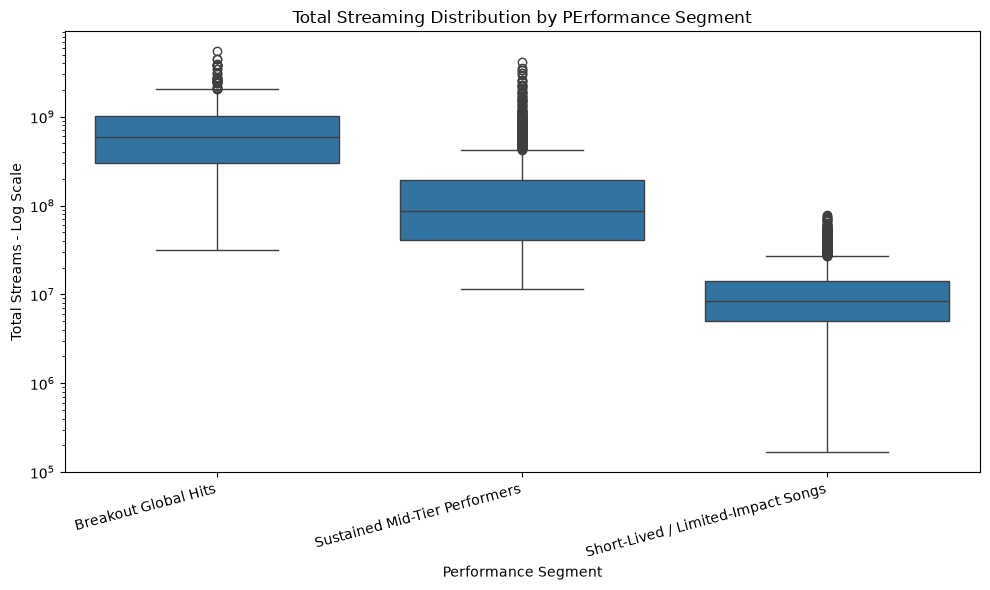

In [30]:
# Compare total streams across segments
# Because total is highly skewed, use a logarithmic y-axis

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=seg_df,
    x="segment",
    y="total"
)

plt.yscale("log")

plt.xlabel("Performance Segment")
plt.ylabel("Total Streams - Log Scale")
plt.title("Total Streaming Distribution by PErformance Segment")

plt.xticks(
    rotation=15,
    ha="right"
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "total_streams_by_segment.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

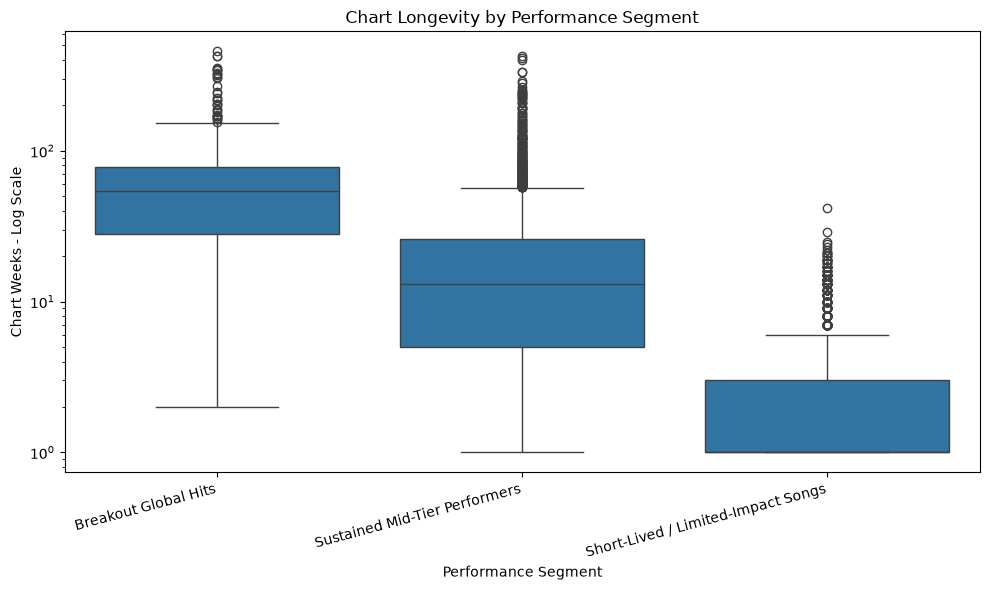

In [32]:
# Compare chart longevity

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=seg_df,
    x="segment",
    y="wks"
)

plt.yscale("log")

plt.xlabel("Performance Segment")
plt.ylabel("Chart Weeks - Log Scale")
plt.title("Chart Longevity by Performance Segment")

plt.xticks(
    rotation=15,
    ha="right"
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "longevity_by_segment.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [33]:
# Top-10 presence by segment

seg_df["top10_status"] = np.where(
    seg_df["t10"] > 0,
    "Reached Top 10",
    "Did Not Reach Top 10"
)

In [34]:
# Then

segment_top10 = pd.crosstab(
    seg_df["segment"],
    seg_df["top10_status"],
    normalize="index"
) * 100

display(
    segment_top10.round(2)
)

top10_status,Did Not Reach Top 10,Reached Top 10
segment,,
Breakout Global Hits,0.00,100.00
Short-Lived / Limited-Impact Songs,100.00,0.00
Sustained Mid-Tier Performers,94.13,5.87


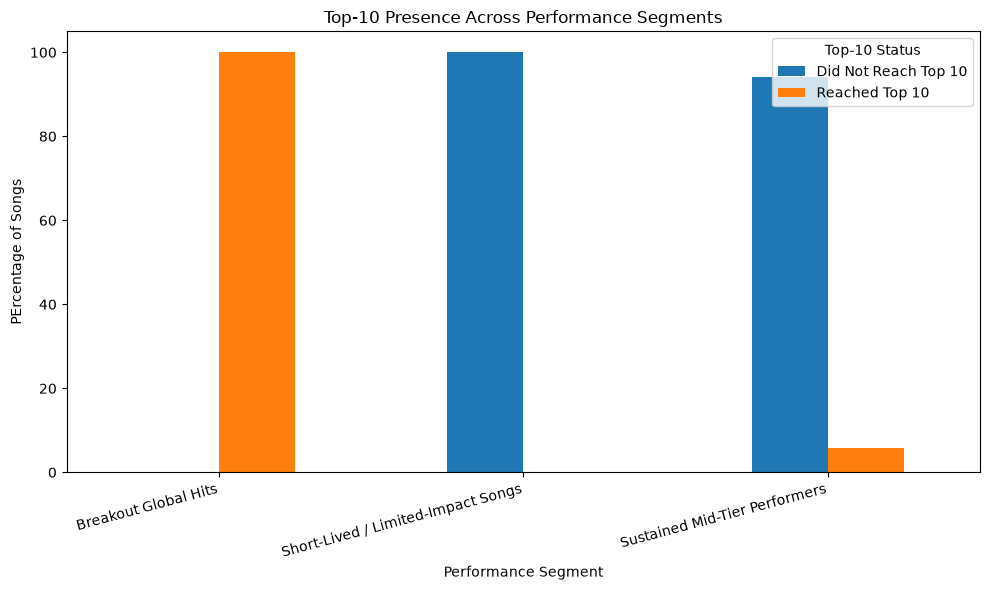

In [35]:
# Visualize

segment_top10.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.xlabel("Performance Segment")
plt.ylabel("PErcentage of Songs")
plt.title("Top-10 Presence Across Performance Segments")

plt.xticks(
    rotation=15,
    ha="right"
)

plt.legend(
    title="Top-10 Status"
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "top10_presence_by_segment.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [37]:
# Peak-position distribution

seg_df["peak_group"] = pd.cut(
    seg_df["pk"],
    bins=[
        0,
        1,
        3,
        5,
        10,
        25,
        50,
        100,
        246
    ],
    labels=[
        "#1",
        "Top 3",
        "Top 5",
        "Top 10",
        "11-25",
        "26-50",
        "51-100",
        "101+"
    ],
    include_lowest=True
)

In [38]:
# Then

segment_peak = pd.crosstab(
    seg_df["segment"],
    seg_df["peak_group"],
    normalize="index"
) * 100

display(
    segment_peak.round(2)
)

peak_group,#1,Top 3,Top 5,Top 10,11-25,26-50,51-100,101+
segment,,,,,,,,
Breakout Global Hits,22.22,30.64,18.69,28.45,0.00,0.00,0.00,0.00
Short-Lived / Limited-Impact Songs,0.00,0.00,0.00,0.00,0.13,2.35,22.57,74.95
Sustained Mid-Tier Performers,0.05,0.49,0.84,4.48,26.11,31.25,30.95,5.82


In [39]:
# Segment x longevity

seg_df["longevity_group"] = pd.cut(
    seg_df["wks"],
    bins=[0,4,12,26,52,np.inf],
    labels=[
        "Short (1-4)",
        "Moderate (5-12)",
        "Long (13-26)",
        "Very Long (27-52)",
        "Exceptional (53+)"
    ]
)

segment_longevity = pd.crosstab(
    seg_df["segment"],
    seg_df["longevity_group"],
    normalize="index"
) * 100

display(
    segment_longevity.round(2)
)

longevity_group,Short (1-4),Moderate (5-12),Long (13-26),Very Long (27-52),Exceptional (53+)
segment,,,,,
Breakout Global Hits,4.21,7.07,11.62,25.42,51.68
Short-Lived / Limited-Impact Songs,85.15,12.68,2.11,0.05,0.00
Sustained Mid-Tier Performers,22.64,26.60,26.20,17.64,6.93


This will give you a particularly good portfolio visualization because it shows how the unsupervised clusters correspond to intuitive longevity categories

In [40]:
# 12 Artist representation within segments

artist_segment = (
    seg_df
    .groupby(
        ["segment", "artist name"]
    )
    .size()
    .reset_index(name="songs")
)

artist_segment["rank"] = (
    artist_segment
    .groupby("segment")["songs"]
    .rank(
        method="first",
        ascending=False
    )
)

top_artists_by_segment = (
    artist_segment[
        artist_segment["rank"] <= 10
    ]
    .sort_values(
        ["segment", "rank"]
    )
)

display(
    top_artists_by_segment
)

,segment,artist name,songs,rank
214,Breakout Global Hits,Taylor Swift,36,1.0
58,Breakout Global Hits,Drake,28,2.0
19,Breakout Global Hits,Bad Bunny,22,3.0
12,Breakout Global Hits,Ariana Grande,19,4.0
219,Breakout Global Hits,The Weeknd,18,5.0
110,Breakout Global Hits,Justin Bieber,14,6.0
61,Breakout Global Hits,Ed Sheeran,12,7.0
24,Breakout Global Hits,Billie Eilish,10,8.0
171,Breakout Global Hits,Olivia Rodrigo,10,9.0
32,Breakout Global Hits,Calvin Harris,9,10.0


This answers which artists have multiple songs represented within each performance type?

In [41]:
# 13. Representative songs - You already calculated cluster_distance

# Let's now produce a clean table

representative_songs = (
    seg_df
    .sort_values(
        ["segment", "cluster_distance"]
    )
    .groupby("segment")
    .head(10)
)

representative_songs_output = representative_songs[
    [
        "segment",
        "artist name",
        "song name",
        "wks",
        "t10",
        "pk",
        "PkStreams",
        "total",
        "cluster_distance"
    ]
]

display(
    representative_songs_output
)

,segment,artist name,song name,wks,t10,pk,PkStreams,total,cluster_distance
600,Breakout Global Hits,Kodak Black,ZEZE,39,8,3,29095302,475296500,0.121381
419,Breakout Global Hits,Yandel,Yandel 150,35,7,8,26978839,631334119,0.304757
395,Breakout Global Hits,Kenya Grace,Strangers,33,7,4,31732751,673225048,0.353988
357,Breakout Global Hits,ROSALÍA,DESPECHÁ,44,8,5,30330456,721187001,0.400645
721,Breakout Global Hits,Rae Sremmurd,Black Beatles,44,8,1,32026901,400833823,0.404492
431,Breakout Global Hits,Quevedo,Columbia,35,8,7,29578111,614422607,0.413705
306,Breakout Global Hits,Dua Lipa,Dance The Night,48,9,5,33252200,800461212,0.447308
543,Breakout Global Hits,Becky G,MAMIII,38,7,5,23135757,508562481,0.464218
800,Breakout Global Hits,Lil Pump,Gucci Gang,32,7,6,23269004,360034188,0.506562
631,Breakout Global Hits,Luis Fonsi,Échame La Culpa,40,8,7,19056515,455074445,0.524925


These are representative examples, not a ranking.

In [42]:
# 14. Save all Notebook outputs

cluster_evaluation.to_csv(
    TABLE_DIR / "cluster_evaluation.csv",
    index=False 
)

cluster_profile.to_csv(
    TABLE_DIR / "cluster_profile.csv"
)

segment_distribution.to_csv(
    TABLE_DIR / "segment_distribution.csv"
)

segment_summary.to_csv(
    TABLE_DIR / "segment_summary.csv"
)

segment_top10.to_csv(
    TABLE_DIR / "segment_top10_distribution.csv"
)

segment_peak.to_csv(
    TABLE_DIR / "segment_peak_distribution.csv"
)

segment_longevity.to_csv(
    TABLE_DIR / "segment_longevity_distribution.csv"
)

top_artists_by_segment.to_csv(
    TABLE_DIR / "top_artists_by_segment.csv"
)

representative_songs.to_csv(
    TABLE_DIR / "representative_songs_by_segment.csv",
    index=False
)

print("All segmentation tables saved.")

All segmentation tables saved.


In [43]:
# 15. Save the final segmented dataset

SEGMENTED_DATA_PATH = (
    PROCESSED_DIR
    / "spotify_hit_segments.csv"
)

seg_df.to_csv(
    SEGMENTED_DATA_PATH,
    index=False
)

print(
    "Saved segmented dataset to:"
)

print(SEGMENTED_DATA_PATH)

Saved segmented dataset to:
C:\Users\Sanu\OneDrive\Desktop\Spotify-Global-Hit-Intelligence\data\processed\spotify_hit_segments.csv


### Final Conclusions

### Three Distinct Performance Profiles

The K-Means analysis identified three distinct song-performance segments.

#### 1. Short-Lived / Limited-Impact Songs

This is the largest segment, representing approximately 47% of songs.

Songs in the typically have very short chart runs, weaker peak positions, and lower cumulative streams.

#### 2. Sustained Mid-Tier Performers

This segment represents approximately 46% of songs.

These songs demonstrate greater chart longevity and substantially higher cumulative streams than the short-lived group, but generally do not have extensive Top-10 exposure.

#### 3. Breakout Global Hits

This is the smallest segment, representing approximately 7% of the songs.

These songs exhibit a combination of long chart longevity, stong peak posiitons, significant Top-10 exposure, high peak streaming levels and high cumulative streams.

#### Key Finding

Global chart success is multidimensional

A song can have sustained chart presence without extensive Top-10 exposure, while a smaller group of songs combines longevity, strong peak performance, Top-10 presence, and very high streaming volume.

#### Methodological Note

The clusters describe patterns in observed chart performance rather than predicting future success.

K-Means was applied after log transformation and standardization of performance variables to reduce the influence of extreme streaming and longevity values.

PCA was used only for visualization. The first two principal components explained approximately 81.6% of the variance in the standardized clustering feature space.
